# 02 - Model Development and Experiment Tracking

Models are selected, tuned and compared on the cleaned heart disease data, and
the runs are recorded in MLflow. The steps common to all models are functions
in `src/`.

1. Data split
2. Evaluation method
3. Model selection
4. `ca` as categorical or numerical
5. Logistic Regression

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

# project root, one level above notebooks/
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.data_prep import CATEGORICAL, NUMERIC
from src.evaluation import (
    RANDOM_STATE,
    build_metrics_table,
    create_cv_folds,
    cross_val_probabilities,
    plot_confusion_matrix,
    plot_roc_curve,
    readable_metrics,
    run_grid_search,
    split_data,
)
from src.preprocessing import make_pipeline
from src.tracking import log_model_runs

pd.set_option("display.width", 200)

## 1. Data split

80% training and 20% test, stratified, with a fixed seed. The test set is
used only once, at the end, for the champion model.

In [2]:
X_train, X_test, y_train, y_test = split_data()

split = pd.DataFrame({
    "patients": [len(y_train), len(y_test)],
    "with disease": [int(y_train.sum()), int(y_test.sum())],
    "disease share (%)": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)],
}, index=["training", "test"])
split

,patients,with disease,disease share (%)
training,242,111,45.9
test,61,28,45.9


The objective of the experiment is to select the best model. It has to beat
these scores, which can be got without learning anything from the data:

- Accuracy: about 54%. A model that predicts "no disease" for every patient
  gets this, because 54% of the patients do not have the disease.
- ROC-AUC: 0.5. Random guessing gives this.

## 2. Evaluation method

- 10-fold stratified cross-validation on the training patients.
- Metrics: accuracy, precision, recall, F1 and ROC-AUC, as mean and standard
  deviation over the folds.
- Grid search for tuning. The best setting of a model is the one with the
  highest mean ROC-AUC. If two settings are equal, the simpler one is taken.
- All runs are recorded in MLflow.

In [3]:
folds = create_cv_folds()
folds

StratifiedKFold(n_splits=10, random_state=42, shuffle=True)

## 3. Model selection

Points considered while choosing the models:

- Only 242 patients are available for training, so models that need a lot of
  data were left out.
- Each prediction has to come with its confidence, so the model must be able
  to give a probability.
- The EDA showed non-linear patterns, for example for `ca` and `slope`.
- The outliers were kept in the data.
- It should be possible to explain a prediction.

Models selected:

- Logistic Regression: simple and easy to explain. Used as the reference
  model.
- Random Forest: handles non-linear patterns and outliers.
- Gradient Boosting: tree-based and usually accurate on table data, but can
  overfit small data.
- Support Vector Machine: a different approach that works well on small data.
  It is the hardest to explain.

## 4. `ca` as categorical or numerical

`ca` is a count from 0 to 3. In the EDA it was treated as categorical, because
the disease share did not rise in equal steps with the count (notebook 01,
section 11). Both forms are tried here on the reference model with its default
setting (`C` = 1), on the same folds.

In [4]:
model_name = "Logistic Regression"
default_grid = {"model__C": [1.0]}

# ca moved from the categorical list to the numerical list
numeric_with_ca = NUMERIC + ["ca"]
categorical_without_ca = CATEGORICAL.copy()
categorical_without_ca.remove("ca")

ca_pipelines = {
    "categorical": make_pipeline(LogisticRegression(random_state=RANDOM_STATE)),
    "numerical": make_pipeline(
        LogisticRegression(random_state=RANDOM_STATE),
        numeric=numeric_with_ca,
        categorical=categorical_without_ca,
    ),
}

ca_tables = []
for ca_form, ca_pipeline in ca_pipelines.items():
    ca_search = run_grid_search(ca_pipeline, default_grid, X_train, y_train, folds)
    ca_table = build_metrics_table(ca_search)
    log_model_runs(
        f"{model_name} (ca {ca_form})", ca_pipeline, ca_search, ca_table,
        X_train, y_train, folds, tags={"experiment": "ca form"},
    )
    ca_table.insert(0, "ca", ca_form)
    ca_tables.append(ca_table)

readable_metrics(pd.concat(ca_tables, ignore_index=True))

Logged to MLflow: Logistic Regression (ca categorical), 1 combinations.
Logged to MLflow: Logistic Regression (ca numerical), 1 combinations.


,ca,C,accuracy,precision,recall,f1,roc_auc
0,categorical,1.0,0.847 ± 0.063,0.879 ± 0.100,0.793 ± 0.107,0.826 ± 0.066,0.904 ± 0.052
1,numerical,1.0,0.831 ± 0.055,0.856 ± 0.091,0.776 ± 0.106,0.807 ± 0.061,0.907 ± 0.050


Observations

The two forms give almost the same result. ROC-AUC is 0.904 with `ca` as
categorical and 0.907 as numerical. This gap is much smaller than the standard
deviation across the folds (about 0.05). The other four metrics are slightly
higher for the categorical form. As there is no clear difference, `ca` is kept
as categorical, as decided in the EDA.

## 5. Logistic Regression

Reference model. The default L2 penalty is used and its strength `C` is tuned.
A smaller `C` gives a simpler model. The default value, `C` = 1, is one of the
values tried.

In [5]:
model_name = "Logistic Regression"

pipeline = make_pipeline(LogisticRegression(random_state=RANDOM_STATE))

# "model__C" is the setting C of the pipeline step named "model"
grid = {"model__C": [0.01, 0.1, 1, 10]}

In [6]:
search = run_grid_search(pipeline, grid, X_train, y_train, folds)
metrics_table = build_metrics_table(search)

print("Combinations tried:", len(metrics_table))
print("Best setting by ROC-AUC:", search.best_params_)

Combinations tried: 4
Best setting by ROC-AUC: {'model__C': 0.1}


In [7]:
# recorded in MLflow: a parent run for the model, a child run for each
# combination, and the trained model of the best setting
log_model_runs(model_name, pipeline, search, metrics_table, X_train, y_train, folds)

Logged to MLflow: Logistic Regression, 4 combinations.


In [8]:
# mean ± std over the 10 folds
readable_metrics(metrics_table)

,C,accuracy,precision,recall,f1,roc_auc
0,0.01,0.806 ± 0.069,0.880 ± 0.124,0.694 ± 0.082,0.768 ± 0.069,0.888 ± 0.059
1,0.10,0.831 ± 0.050,0.852 ± 0.097,0.784 ± 0.092,0.810 ± 0.049,0.905 ± 0.048
2,1.00,0.847 ± 0.063,0.879 ± 0.100,0.793 ± 0.107,0.826 ± 0.066,0.904 ± 0.052
3,10.00,0.839 ± 0.063,0.860 ± 0.097,0.794 ± 0.112,0.818 ± 0.067,0.902 ± 0.052


In [9]:
# default setting (C = 1) against the best setting
default_row = metrics_table[metrics_table["C"] == 1]
best_row = metrics_table.loc[[search.best_index_]]

comparison = pd.concat([default_row, best_row])
comparison.insert(0, "setting", ["default", "best"])
readable_metrics(comparison)

,setting,C,accuracy,precision,recall,f1,roc_auc
2,default,1.0,0.847 ± 0.063,0.879 ± 0.100,0.793 ± 0.107,0.826 ± 0.066,0.904 ± 0.052
1,best,0.1,0.831 ± 0.050,0.852 ± 0.097,0.784 ± 0.092,0.810 ± 0.049,0.905 ± 0.048


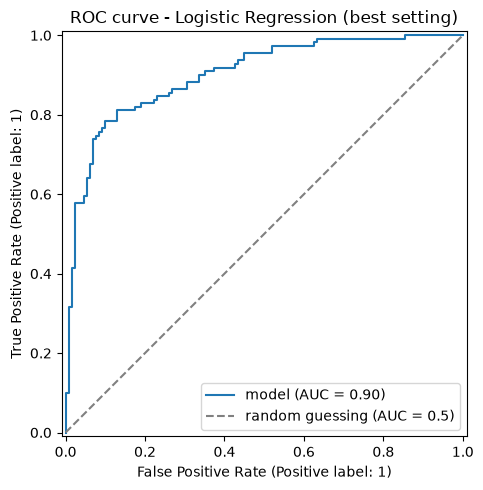

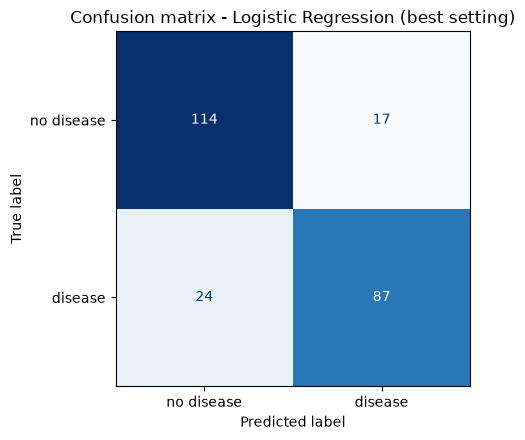

In [10]:
# plots for the best setting, from the cross-validation predictions
best_pipeline = clone(pipeline).set_params(**search.best_params_)
probability = cross_val_probabilities(best_pipeline, X_train, y_train, folds)

plot_roc_curve(y_train, probability, f"ROC curve - {model_name} (best setting)")
plot_confusion_matrix(y_train, probability, f"Confusion matrix - {model_name} (best setting)")
plt.show()

Observations

- The best setting is `C` = 0.1, with a mean ROC-AUC of 0.905.
- ROC-AUC stays between 0.902 and 0.905 for `C` = 0.1, 1 and 10, so the model
  is not sensitive to `C` in this range.
- Tuning gave no real gain over the default setting (0.905 against 0.904).

Recall is 0.784 at the best setting, so about 22% of the patients with disease
are missed.

## Viewing the runs in MLflow

```
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```